# Pneumonia Classification with a Vision Transformer (ViT)

This notebook evaluates a pretrained Hugging Face Vision Transformer on chest X-ray images, then compares fine-tuning and inference-time modifications.

> **Scope:** This is an educational machine-learning experiment, not a clinically validated diagnostic system. Do not use its predictions for patient care.

## Project overview

The notebook compares the downloaded reference checkpoint with fine-tuned variants and inference-time strategies. The reference checkpoint was trained before this notebook; it is **not a model trained from scratch here**.

| Experiment | Configuration | Purpose |
|---|---|---|
| A | Reference ViT, raw images | Baseline evaluation |
| A2 | Reference ViT, CLAHE images | Test CLAHE at inference time |
| B | Fine-tuning with class-weighted loss | Adapt the reference checkpoint to our training split |
| B2 | Fine-tuning without class weights | Ablation for the class-weighting choice |
| C | Fine-tuning with class weights and CLAHE | Evaluate the combined modification |
| D | Reference ViT with test-time augmentation (TTA) | Average predictions across four views |
| E | Reference ViT with raw/CLAHE fusion | Average predictions from two preprocessing views |
| F | Reference ViT with fusion and TTA | Combine the inference-time strategies |

## Run this notebook in Google Colab

1. Open the notebook in Colab and select **Runtime → Change runtime type → T4 GPU** (or another available GPU).
2. Run the cells **from top to bottom**. The first code cell installs dependencies.
3. When prompted, allow the notebook to download the dataset from Kaggle through `kagglehub` and the model/processor from Hugging Face.
4. The results are written to `/content/results/`; the fine-tuned checkpoint is saved under `/content/vit_final/`. These are temporary Colab files unless you download them or copy them to Drive.

## Dataset and model

- **Dataset:** [Chest X-Ray Images (Pneumonia)](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia), associated with Kermany et al. (2018).
- **Reference checkpoint:** [`lxyuan/vit-xray-pneumonia-classification`](https://huggingface.co/lxyuan/vit-xray-pneumonia-classification).
- **Backbone family:** [`google/vit-base-patch16-224-in21k`](https://huggingface.co/google/vit-base-patch16-224-in21k).

The official test folder is retained as the evaluation holdout in this notebook. The official validation folder is not used because it contains very few images; instead, a stratified validation split is sampled from the training folder. See Section 2 for the exact split logic.

## Important interpretation notes

- Results from this notebook are only directly comparable when the data split, preprocessing, threshold, and evaluation protocol match.
- The reference checkpoint may have been trained on overlapping copies of this public dataset. Treat its test score as a **reference result**, not as an independent, leakage-free estimate.
- The test set is modest in size; small differences in metrics may reflect sampling variability.
- This is a binary classification exercise (`NORMAL` vs `PNEUMONIA`), not a substitute for professional medical interpretation.

## Reproducibility

A fixed random seed is used for the split and training setup. GPU availability, dependency versions, and upstream model/dataset revisions can still affect exact results. The notebook prints the device and model label mapping during setup.


In [1]:
!pip -q install transformers kagglehub opencv-python-headless scikit-learn
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU - switch runtime to T4")

GPU: Tesla T4


## 1. Imports and configuration

Set the random seed, model identifier, image size, training hyperparameters, and device. The settings below are intentionally conservative for a Colab T4 GPU.

In [2]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import gc, json, random, time, glob
import numpy as np, pandas as pd, cv2, torch, torch.nn as nn
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_auc_score
import matplotlib.pyplot as plt
from transformers import AutoConfig, AutoImageProcessor, AutoModelForImageClassification, get_cosine_schedule_with_warmup

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

MODEL_NAME  = "lxyuan/vit-xray-pneumonia-classification"
IMG_SIZE    = 224
BATCH_SIZE  = 16        # training batch size (small to be safe on a T4)
EVAL_BATCH  = 32
FT_EPOCHS   = 5         # fine-tuning epochs (model is already trained, so few are needed)
FT_PATIENCE = 2         # early stopping on validation loss
FT_LR       = 2e-5      # low LR: we are adapting an already fine-tuned model
WEIGHT_DECAY = 0.01
CLAHE_CLIP, CLAHE_TILE = 2.0, (8, 8)
MIN_VAL_ACC = 0.60      # sanity floor: a fine-tune below this is flagged as failed

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_cuda = device.type == "cuda"
print("Device:", device)

Device: cuda


## 2. Download the dataset and create the splits

The official `test` folder (expected to contain 624 images in this dataset release) is kept as the holdout. The official `val` folder contains very few images, so the notebook creates a stratified validation split from the official training folder instead.

The split is reproducible through `SEED`. The test set is not used for early stopping or model selection in the fine-tuning function. Because the downloaded reference checkpoint may already have seen overlapping images during its original training, the reference-based results should not be interpreted as a fully independent clinical benchmark.

In [3]:
import kagglehub
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
root = None
for dp, dn, fn in os.walk(path):
    if {"train", "test"}.issubset(set(dn)):
        root = dp; break
print("Dataset root:", root)

CLASS_NAMES = ["NORMAL", "PNEUMONIA"]

def list_split(split):
    items = []
    for ci, c in enumerate(CLASS_NAMES):
        for f in glob.glob(os.path.join(root, split, c, "*")):
            if f.lower().endswith((".jpeg", ".jpg", ".png")):
                items.append((f, ci))
    return items

train_all = list_split("train")
test_items = list_split("test")
paths = [p for p, _ in train_all]; labs = [l for _, l in train_all]

tr_p, va_p, tr_l, va_l = train_test_split(paths, labs, test_size=782, stratify=labs, random_state=SEED)
te_p = [p for p, _ in test_items]; te_l = [l for _, l in test_items]

for name, l in [("Train", tr_l), ("Val", va_l), ("Test", te_l)]:
    c = np.bincount(l, minlength=2)
    print(f"{name:5s}: {len(l):5d} images | NORMAL={c[0]} PNEUMONIA={c[1]} | ratio {c[1]/c[0]:.2f}:1")

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset root: /kaggle/input/chest-xray-pneumonia/chest_xray
Train:  4434 images | NORMAL=1140 PNEUMONIA=3294 | ratio 2.89:1
Val  :   782 images | NORMAL=201 PNEUMONIA=581 | ratio 2.89:1
Test :   624 images | NORMAL=234 PNEUMONIA=390 | ratio 1.67:1


## 3. Read the reference model's label mapping

The dataset labels are mapped to the checkpoint's own label IDs by class name. This explicit mapping helps prevent `NORMAL` and `PNEUMONIA` from being silently reversed.

In [4]:
cfg = AutoConfig.from_pretrained(MODEL_NAME)
processor = AutoImageProcessor.from_pretrained(MODEL_NAME)
MEAN, STD = processor.image_mean, processor.image_std
print("Model label mapping:", cfg.id2label)
print("Normalisation mean/std:", MEAN, STD)

name2id = {str(v).upper(): int(k) for k, v in cfg.id2label.items()}
assert set(name2id) == {"NORMAL", "PNEUMONIA"}, f"Unexpected labels: {name2id}"
ds2model = [name2id[c] for c in CLASS_NAMES]   # our class index -> model label id
POS = name2id["PNEUMONIA"]                     # id of the positive class in model space

tr_lm = [ds2model[l] for l in tr_l]
va_lm = [ds2model[l] for l in va_l]
te_lm = [ds2model[l] for l in te_l]
print("POS (pneumonia) id in model space:", POS)

config.json:   0%|          | 0.00/733 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/325 [00:00<?, ?B/s]

Model label mapping: {0: 'NORMAL', 1: 'PNEUMONIA'}
Normalisation mean/std: (0.5, 0.5, 0.5) (0.5, 0.5, 0.5)
POS (pneumonia) id in model space: 1


## 4. Dataset loader and optional CLAHE preprocessing

CLAHE (Contrast Limited Adaptive Histogram Equalization) is applied to the grayscale image before conversion to three channels. The loader resizes images to the ViT input size and applies the reference processor's normalization statistics. Training augmentation is enabled only for the training loader.

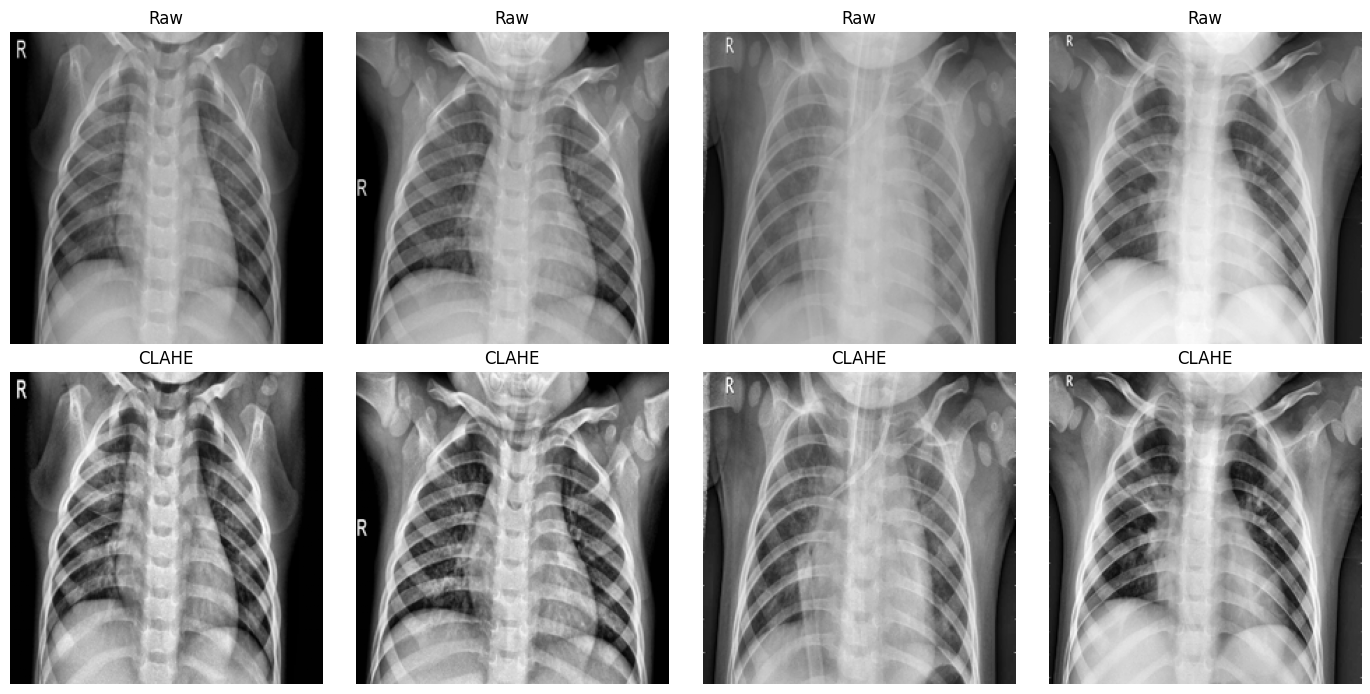

In [5]:
def apply_clahe(gray_np):
    return cv2.createCLAHE(clipLimit=CLAHE_CLIP, tileGridSize=CLAHE_TILE).apply(gray_np)

class XrayDS(Dataset):
    def __init__(self, paths, labels, use_clahe=False, train=False):
        self.paths, self.labels, self.use_clahe = paths, labels, use_clahe
        self.aug = T.Compose([T.RandomHorizontalFlip(), T.RandomRotation(10)]) if train else T.Compose([])
        self.to_tensor = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("L").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
        arr = np.array(img)
        if self.use_clahe:
            arr = apply_clahe(arr)
        img = Image.fromarray(arr).convert("RGB")
        img = self.aug(img)
        return self.to_tensor(img), self.labels[i]

def make_loader(paths, labels, use_clahe, train, bs):
    return DataLoader(XrayDS(paths, labels, use_clahe, train), batch_size=bs, shuffle=train,
                      num_workers=2, pin_memory=use_cuda)

# Visual check: raw vs CLAHE
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for j in range(4):
    img = Image.open(te_p[j * 150]).convert("L").resize((IMG_SIZE, IMG_SIZE))
    ax[0, j].imshow(img, cmap="gray"); ax[0, j].set_title("Raw"); ax[0, j].axis("off")
    ax[1, j].imshow(apply_clahe(np.array(img)), cmap="gray"); ax[1, j].set_title("CLAHE"); ax[1, j].axis("off")
plt.tight_layout(); plt.show()

## 5. Evaluation metrics

The evaluation function reports accuracy, precision, recall/sensitivity, specificity, F1, and ROC AUC, along with confusion-matrix counts. `PNEUMONIA` is treated as the positive class, and the prediction threshold is 0.5.

In [6]:
@torch.no_grad()
def evaluate(model, loader, name):
    model.eval()
    probs, ys = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_cuda):
            logits = model(pixel_values=x).logits
        probs.append(torch.softmax(logits.float(), dim=1)[:, POS].cpu().numpy())
        ys.append((y == POS).numpy().astype(int))
    probs, ys = np.concatenate(probs), np.concatenate(ys)
    preds = (probs >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(ys, preds).ravel()
    res = dict(model=name,
               accuracy=(tp + tn) / len(ys),
               precision=tp / max(tp + fp, 1),
               recall=tp / max(tp + fn, 1),          # sensitivity
               specificity=tn / max(tn + fp, 1),
               f1=2 * tp / max(2 * tp + fp + fn, 1),
               auc=roc_auc_score(ys, probs),
               tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))
    print(f"{name}\n  Acc {res['accuracy']:.4f} | Prec {res['precision']:.4f} | Recall {res['recall']:.4f} | "
          f"Spec {res['specificity']:.4f} | F1 {res['f1']:.4f} | AUC {res['auc']:.4f}\n  TN={tn} FP={fp} FN={fn} TP={tp}")
    return res

results = []

def cleanup():
    gc.collect()
    if use_cuda:
        torch.cuda.empty_cache()

## 6. Experiment A - reference checkpoint, raw images

This checkpoint is downloaded as-is and is **not fine-tuned by this notebook**. It is evaluated on the held-out test folder as a reference baseline. Experiment A2 evaluates the same checkpoint with CLAHE preprocessing.

In [7]:
ref_model = AutoModelForImageClassification.from_pretrained(MODEL_NAME).to(device)
print("Parameters:", f"{sum(p.numel() for p in ref_model.parameters()):,}")

test_raw = make_loader(te_p, te_lm, use_clahe=False, train=False, bs=EVAL_BATCH)
results.append(evaluate(ref_model, test_raw, "A. Reference ViT (zero-shot, raw)"))

# A2: same model, CLAHE applied only at inference time
test_clahe = make_loader(te_p, te_lm, use_clahe=True, train=False, bs=EVAL_BATCH)
results.append(evaluate(ref_model, test_clahe, "A2. Reference ViT (zero-shot, CLAHE input)"))

del ref_model; cleanup()

model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Parameters: 85,800,194
A. Reference ViT (zero-shot, raw)
  Acc 0.9728 | Prec 0.9746 | Recall 0.9821 | Spec 0.9573 | F1 0.9783 | AUC 0.9976
  TN=224 FP=10 FN=7 TP=383
A2. Reference ViT (zero-shot, CLAHE input)
  Acc 0.9631 | Prec 0.9599 | Recall 0.9821 | Spec 0.9316 | F1 0.9708 | AUC 0.9917
  TN=218 FP=16 FN=7 TP=383


## 7. Fine-tuning function

The following function fine-tunes the existing reference checkpoint on the notebook's training split. Configurable changes include class-weighted cross-entropy and optional CLAHE preprocessing.

Training uses AdamW, a cosine schedule with warmup, mixed precision when CUDA is available, gradient clipping, early stopping on validation loss, and best weights stored on CPU to reduce GPU memory pressure. The checkpoint is already task-fine-tuned, so this is adaptation rather than training a ViT from scratch.

In [8]:
def finetune(use_clahe, tag, use_weights=True):
    model = AutoModelForImageClassification.from_pretrained(MODEL_NAME).to(device)
    train_loader = make_loader(tr_p, tr_lm, use_clahe, True, BATCH_SIZE)
    val_loader   = make_loader(va_p, va_lm, use_clahe, False, EVAL_BATCH)

    counts = np.bincount(tr_lm, minlength=2)
    if use_weights:
        w = counts.sum() / (2.0 * counts)                   # inverse-frequency class weights (model label space)
        print(f"[{tag}] class weights (model id order): {np.round(w, 4)}")
        criterion = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32, device=device))
    else:
        print(f"[{tag}] NO class weights (plain cross-entropy)")
        criterion = nn.CrossEntropyLoss()

    opt = torch.optim.AdamW(model.parameters(), lr=FT_LR, weight_decay=WEIGHT_DECAY)
    total_steps = FT_EPOCHS * len(train_loader)
    sched = get_cosine_schedule_with_warmup(opt, int(0.1 * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=use_cuda)

    hist = dict(train_loss=[], val_loss=[], val_acc=[])
    best_val, best_state, bad = float("inf"), None, 0

    for ep in range(1, FT_EPOCHS + 1):
        t0 = time.time(); model.train(); run, n = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_cuda):
                loss = criterion(model(pixel_values=x).logits.float(), y)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            run += loss.item() * x.size(0); n += x.size(0)

        model.eval(); vl, vc, vn = 0.0, 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_cuda):
                    out = model(pixel_values=x).logits.float()
                vl += criterion(out, y).item() * x.size(0)
                vc += (out.argmax(1) == y).sum().item(); vn += x.size(0)
        tl, vl, va = run / n, vl / vn, vc / vn
        hist["train_loss"].append(tl); hist["val_loss"].append(vl); hist["val_acc"].append(va)
        print(f"[{tag}] epoch {ep}/{FT_EPOCHS} | train_loss {tl:.4f} | val_loss {vl:.4f} | val_acc {va:.4f} | {time.time()-t0:.0f}s")

        if vl < best_val:
            best_val, bad = vl, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= FT_PATIENCE:
                print(f"[{tag}] early stopping at epoch {ep}"); break

    model.load_state_dict(best_state)
    if max(hist["val_acc"]) < MIN_VAL_ACC:
        print(f"[{tag}] WARNING: validation accuracy never reached {MIN_VAL_ACC} - this run failed, re-run it.")
    return model, hist

def plot_hist(h, title):
    plt.figure(figsize=(6, 3.5))
    plt.plot(h["train_loss"], label="train loss"); plt.plot(h["val_loss"], label="val loss")
    plt.title(title); plt.xlabel("epoch"); plt.legend(); plt.tight_layout(); plt.show()

## 8. Experiment B - fine-tuning with class-weighted loss

Fine-tune on raw images using inverse-frequency class weights.

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[B] class weights (model id order): [1.9447 0.673 ]
[B] epoch 1/5 | train_loss 0.0693 | val_loss 0.0637 | val_acc 0.9731 | 77s
[B] epoch 2/5 | train_loss 0.0568 | val_loss 0.0403 | val_acc 0.9910 | 69s
[B] epoch 3/5 | train_loss 0.0362 | val_loss 0.0521 | val_acc 0.9898 | 62s
[B] epoch 4/5 | train_loss 0.0178 | val_loss 0.0357 | val_acc 0.9936 | 61s
[B] epoch 5/5 | train_loss 0.0163 | val_loss 0.0377 | val_acc 0.9923 | 61s


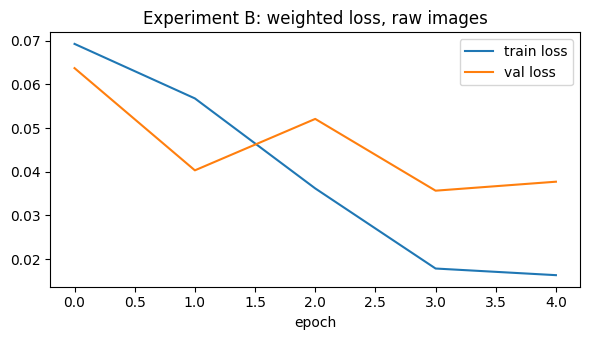

B. ViT fine-tuned (our split + class weights)
  Acc 0.9151 | Prec 0.8821 | Recall 0.9974 | Spec 0.7778 | F1 0.9362 | AUC 0.9929
  TN=182 FP=52 FN=1 TP=389


In [9]:
model_b, hist_b = finetune(use_clahe=False, tag="B")
plot_hist(hist_b, "Experiment B: weighted loss, raw images")
results.append(evaluate(model_b, test_raw, "B. ViT fine-tuned (our split + class weights)"))
del model_b; cleanup()

## 8b. Experiment B2 - fine-tuning without class weights

This ablation uses the same split and fine-tuning setup as B, but uses ordinary cross-entropy. Comparing B and B2 helps assess the effect of class weighting; it does not establish causality beyond this experimental setup.

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[B2] NO class weights (plain cross-entropy)
[B2] epoch 1/5 | train_loss 0.0575 | val_loss 0.0368 | val_acc 0.9898 | 74s
[B2] epoch 2/5 | train_loss 0.0445 | val_loss 0.0539 | val_acc 0.9808 | 69s
[B2] epoch 3/5 | train_loss 0.0326 | val_loss 0.0237 | val_acc 0.9936 | 64s
[B2] epoch 4/5 | train_loss 0.0181 | val_loss 0.0382 | val_acc 0.9898 | 66s
[B2] epoch 5/5 | train_loss 0.0121 | val_loss 0.0251 | val_acc 0.9936 | 62s
[B2] early stopping at epoch 5


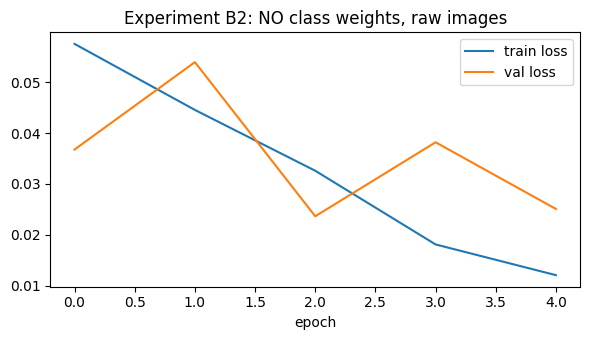

B2. ViT fine-tuned (our split, NO class weights)
  Acc 0.8910 | Prec 0.8515 | Recall 1.0000 | Spec 0.7094 | F1 0.9198 | AUC 0.9917
  TN=166 FP=68 FN=0 TP=390


In [10]:
model_b2, hist_b2 = finetune(use_clahe=False, tag="B2", use_weights=False)
plot_hist(hist_b2, "Experiment B2: NO class weights, raw images")
results.append(evaluate(model_b2, test_raw, "B2. ViT fine-tuned (our split, NO class weights)"))
del model_b2; cleanup()

## 9. Experiment C - fine-tuning with class weights and CLAHE

This experiment combines weighted loss with CLAHE preprocessing.

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[C] class weights (model id order): [1.9447 0.673 ]
[C] epoch 1/5 | train_loss 0.0902 | val_loss 0.0504 | val_acc 0.9859 | 63s
[C] epoch 2/5 | train_loss 0.0682 | val_loss 0.0581 | val_acc 0.9834 | 64s
[C] epoch 3/5 | train_loss 0.0448 | val_loss 0.0473 | val_acc 0.9834 | 64s
[C] epoch 4/5 | train_loss 0.0295 | val_loss 0.0490 | val_acc 0.9898 | 64s
[C] epoch 5/5 | train_loss 0.0220 | val_loss 0.0420 | val_acc 0.9898 | 64s


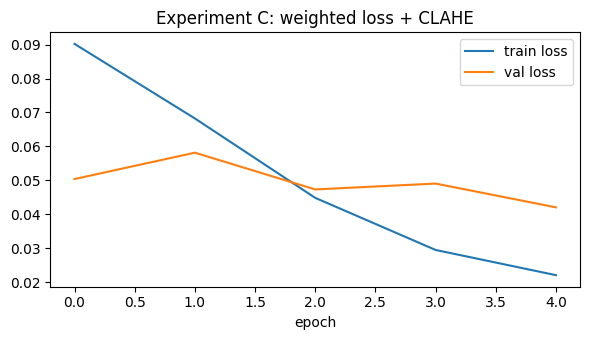

C. ViT fine-tuned (class weights + CLAHE)
  Acc 0.8974 | Prec 0.8606 | Recall 0.9974 | Spec 0.7308 | F1 0.9240 | AUC 0.9896
  TN=171 FP=63 FN=1 TP=389


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [11]:
model_c, hist_c = finetune(use_clahe=True, tag="C")
plot_hist(hist_c, "Experiment C: weighted loss + CLAHE")
results.append(evaluate(model_c, test_clahe, "C. ViT fine-tuned (class weights + CLAHE)"))

os.makedirs("/content/vit_final", exist_ok=True)
model_c.save_pretrained("/content/vit_final"); processor.save_pretrained("/content/vit_final")
del model_c; cleanup()

## 9b. Experiments D, E, and F - inference-time add-ons

These experiments reload the **unchanged reference checkpoint** and do not retrain it.

| Experiment | Strategy | Description |
|---|---|---|
| D | Test-time augmentation (TTA) | Average predictions across the original image, horizontal flip, +5° rotation, and −5° rotation |
| E | Raw/CLAHE fusion | Average predictions from raw and CLAHE-preprocessed inputs |
| F | Fusion + TTA | Combine both inference-time strategies |

All variants are reported for transparency. Since they are evaluated on the same test set, use caution when interpreting small differences and avoid treating the best test score as an unbiased model-selection result.

In [12]:
import torchvision.transforms.functional as TF

ref_model = AutoModelForImageClassification.from_pretrained(MODEL_NAME).to(device).eval()

# TTA views, applied on the normalised image tensor
identity = lambda x: x
hflip    = lambda x: torch.flip(x, dims=[3])
rot_p5   = lambda x: TF.rotate(x, 5,  interpolation=TF.InterpolationMode.BILINEAR)
rot_m5   = lambda x: TF.rotate(x, -5, interpolation=TF.InterpolationMode.BILINEAR)
TTA_VIEWS = [identity, hflip, rot_p5, rot_m5]

@torch.no_grad()
def get_probs(model, loader, views):
    model.eval(); out, ys = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        ps = []
        for v in views:
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_cuda):
                logits = model(pixel_values=v(x)).logits
            ps.append(torch.softmax(logits.float(), dim=1)[:, POS])
        out.append(torch.stack(ps).mean(0).cpu().numpy())
        ys.append((y == POS).numpy().astype(int))
    return np.concatenate(out), np.concatenate(ys)

def metrics_from_probs(probs, ys, name):
    preds = (probs >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(ys, preds).ravel()
    res = dict(model=name,
               accuracy=(tp + tn) / len(ys),
               precision=tp / max(tp + fp, 1),
               recall=tp / max(tp + fn, 1),
               specificity=tn / max(tn + fp, 1),
               f1=2 * tp / max(2 * tp + fp + fn, 1),
               auc=roc_auc_score(ys, probs),
               tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))
    print(f"{name}\n  Acc {res['accuracy']:.4f} | Prec {res['precision']:.4f} | Recall {res['recall']:.4f} | "
          f"Spec {res['specificity']:.4f} | F1 {res['f1']:.4f} | AUC {res['auc']:.4f}\n  TN={tn} FP={fp} FN={fn} TP={tp}")
    return res

# Probabilities for each view family (test loaders are not shuffled, so rows line up)
p_raw_1,   ys = get_probs(ref_model, test_raw,   [identity])
p_raw_tta, _  = get_probs(ref_model, test_raw,   TTA_VIEWS)
p_cl_1,    _  = get_probs(ref_model, test_clahe, [identity])
p_cl_tta,  _  = get_probs(ref_model, test_clahe, TTA_VIEWS)

results.append(metrics_from_probs(p_raw_tta, ys, "D. Reference ViT + TTA (no retraining)"))
results.append(metrics_from_probs((p_raw_1 + p_cl_1) / 2, ys, "E. Reference ViT + raw/CLAHE fusion (no retraining)"))
results.append(metrics_from_probs((p_raw_tta + p_cl_tta) / 2, ys, "F. Reference ViT + raw/CLAHE fusion + TTA (no retraining)"))

del ref_model; cleanup()

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

D. Reference ViT + TTA (no retraining)
  Acc 0.9760 | Prec 0.9723 | Recall 0.9897 | Spec 0.9530 | F1 0.9809 | AUC 0.9975
  TN=223 FP=11 FN=4 TP=386
E. Reference ViT + raw/CLAHE fusion (no retraining)
  Acc 0.9792 | Prec 0.9772 | Recall 0.9897 | Spec 0.9615 | F1 0.9834 | AUC 0.9963
  TN=225 FP=9 FN=4 TP=386
F. Reference ViT + raw/CLAHE fusion + TTA (no retraining)
  Acc 0.9696 | Prec 0.9603 | Recall 0.9923 | Spec 0.9316 | F1 0.9760 | AUC 0.9965
  TN=218 FP=16 FN=3 TP=387


## 10. Results - metrics, plots, and CNN comparison

The table and plots below summarize the experiments run above. CNN values are copied from earlier project notebooks and are included for context; comparisons are only fair if the evaluation sets and protocols match.

,model,accuracy,precision,recall,specificity,f1,auc
0,"A. Reference ViT (zero-shot, raw)",0.9728,0.9746,0.9821,0.9573,0.9783,0.9976
1,"A2. Reference ViT (zero-shot, CLAHE input)",0.9631,0.9599,0.9821,0.9316,0.9708,0.9917
2,B. ViT fine-tuned (our split + class weights),0.9151,0.8821,0.9974,0.7778,0.9362,0.9929
3,"B2. ViT fine-tuned (our split, NO class weights)",0.8910,0.8515,1.0000,0.7094,0.9198,0.9917
4,C. ViT fine-tuned (class weights + CLAHE),0.8974,0.8606,0.9974,0.7308,0.9240,0.9896
5,D. Reference ViT + TTA (no retraining),0.9760,0.9723,0.9897,0.9530,0.9809,0.9975
6,E. Reference ViT + raw/CLAHE fusion (no retrai...,0.9792,0.9772,0.9897,0.9615,0.9834,0.9963
7,F. Reference ViT + raw/CLAHE fusion + TTA (no ...,0.9696,0.9603,0.9923,0.9316,0.9760,0.9965


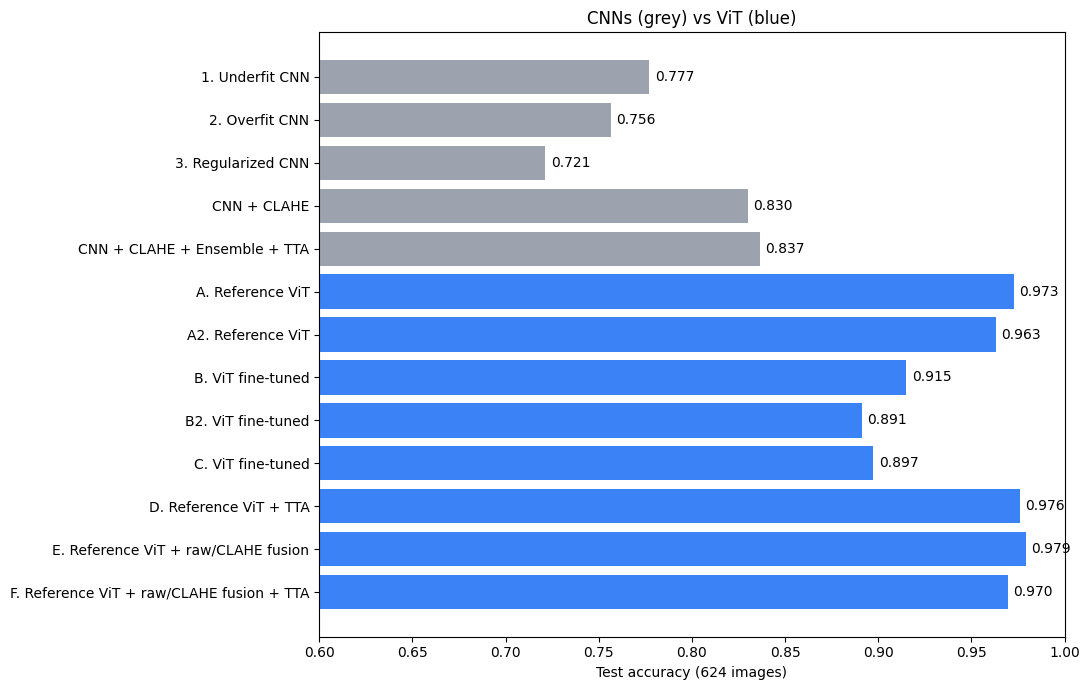

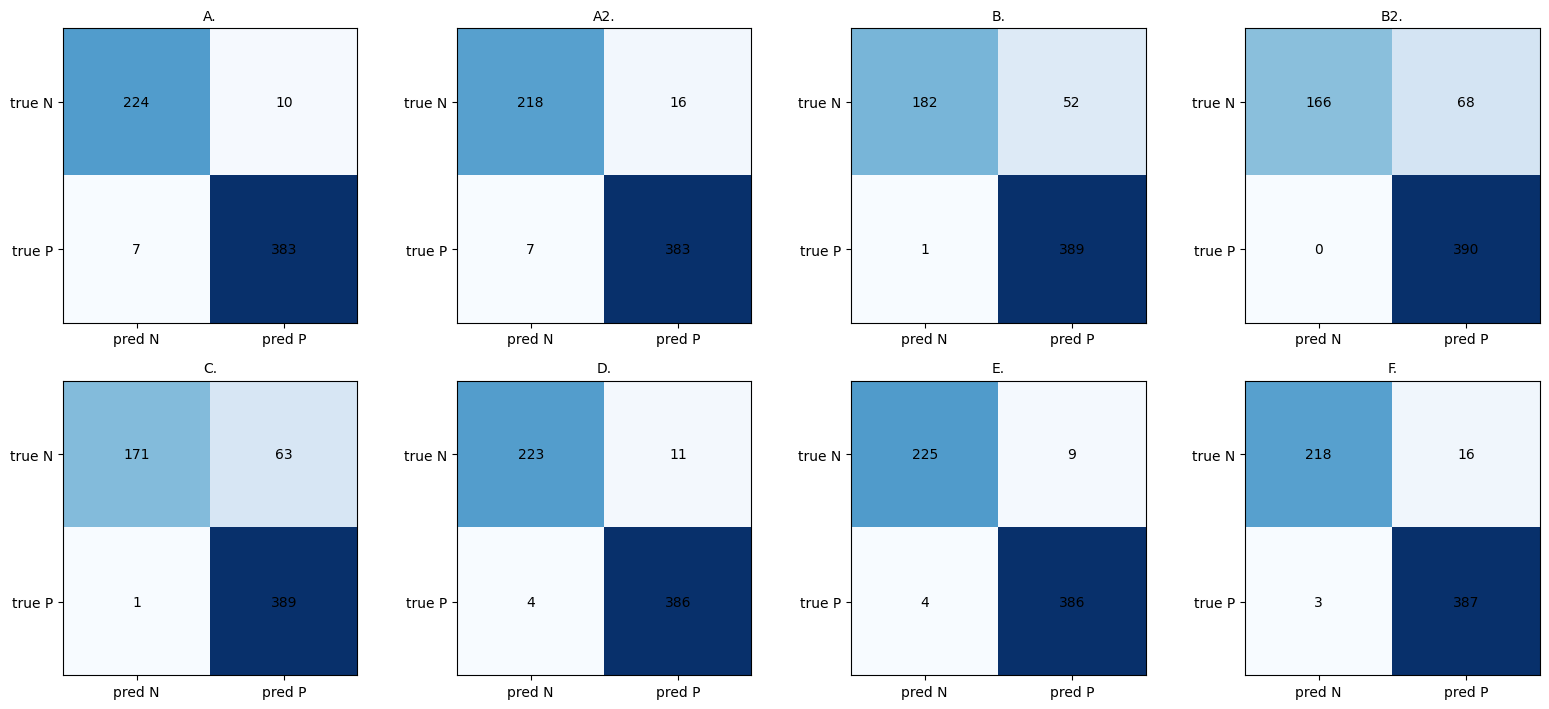

In [13]:
df = pd.DataFrame(results)
show = df[["model", "accuracy", "precision", "recall", "specificity", "f1", "auc"]].round(4)
display(show)

os.makedirs("/content/results", exist_ok=True)
df.to_csv("/content/results/vit_results.csv", index=False)
json.dump(results, open("/content/results/vit_results.json", "w"), indent=2)

# Comparison with our earlier CNN notebooks (test accuracy values taken from notebooks 01-04 outputs)
cnn_prev = {"1. Underfit CNN": 0.7772, "2. Overfit CNN": 0.7564, "3. Regularized CNN": 0.7212,
            "CNN + CLAHE": 0.8301, "CNN + CLAHE + Ensemble + TTA": 0.8365}
labels = list(cnn_prev.keys()) + [r["model"].split("(")[0].strip() for r in results]
vals   = list(cnn_prev.values()) + [r["accuracy"] for r in results]
colors = ["#9ca3af"] * len(cnn_prev) + ["#3b82f6"] * len(results)

plt.figure(figsize=(11, 7))
bars = plt.barh(labels[::-1], vals[::-1], color=colors[::-1])
for b, v in zip(bars, vals[::-1]):
    plt.text(v + 0.003, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center")
plt.xlim(0.6, 1.0); plt.xlabel("Test accuracy (624 images)")
plt.title("CNNs (grey) vs ViT (blue)"); plt.tight_layout(); plt.show()

# Confusion matrices
ncols = 4; nrows = int(np.ceil(len(results) / ncols))
fig, ax = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.6 * nrows))
ax = np.atleast_1d(ax).ravel()
for a in ax[len(results):]:
    a.axis("off")
for a, r in zip(ax, results):
    cm = np.array([[r["tn"], r["fp"]], [r["fn"], r["tp"]]])
    a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            a.text(j, i, cm[i, j], ha="center", va="center")
    a.set_xticks([0, 1]); a.set_xticklabels(["pred N", "pred P"]); a.set_yticks([0, 1]); a.set_yticklabels(["true N", "true P"])
    a.set_title(r["model"].split(".")[0] + ".", fontsize=10)
plt.tight_layout(); plt.show()

## 11. Literature reference points

The figures below were reported by the cited methods under their own experimental protocols. They are contextual reference points, **not a like-for-like benchmark** against this notebook's test set. Verify the original papers and model card before reusing these values in a formal report.

| Method | Reported accuracy |
|---|---:|
| Kermany et al. (2018) | 92.8% |
| VGG16 transfer learning | 96.6% |
| ResNet + AdaBoost-SVM hybrid | 98.1% |
| CLAHE-enhanced CNN | 98.7% |
| `lxyuan/vit-xray-pneumonia-classification` (model card validation split) | 97.4% |

## 12. Discussion checklist

- **Reference vs. fine-tuned variants:** compare A, B, and C across accuracy, recall, and specificity.
- **B vs. B2:** discuss the observed effect of using class weights in this setup.
- **D, E, and F:** describe the inference-time changes and compare each against A. Do not overstate small differences on a 624-image test set.
- **ViT vs. CNN:** note that the ViT checkpoint uses pretraining, while the earlier CNNs were trained from scratch; this is not an equal initialization comparison.
- **Potential data leakage:** the reference checkpoint may have been trained on a copy of this public dataset. Rows A–F use that checkpoint, so their scores are not guaranteed to be leakage-free.
- **Test-set uncertainty:** the test set is relatively small and may differ in distribution from the training split.
- **Sensitivity and specificity:** explain the trade-off between missed pneumonia cases (false negatives) and false alarms (false positives). This notebook is not a clinical tool.

## 13. Attribution and responsible use

- **Reference model:** [`lxyuan/vit-xray-pneumonia-classification`](https://huggingface.co/lxyuan/vit-xray-pneumonia-classification), whose model card identifies its license and upstream backbone.
- **Backbone:** [`google/vit-base-patch16-224-in21k`](https://huggingface.co/google/vit-base-patch16-224-in21k).
- **Dataset:** [Chest X-Ray Images (Pneumonia)](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia), associated with Kermany et al. (2018), *Identifying Medical Diagnoses and Treatable Diseases by Image-Based Deep Learning*, *Cell*.
- **Notebook modifications:** data split, fine-tuning experiments, optional class weighting and CLAHE, metric reporting, TTA, and raw/CLAHE fusion.

Check the current dataset and model-card license terms before redistributing data, model weights, or derivative artifacts. Code licensing does not automatically license third-party images or pretrained weights.


In [14]:
# Optional: download the results files (Colab only)
try:
    from google.colab import files
    files.download("/content/results/vit_results.csv")
except Exception as e:
    print("Skip download:", e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>